# French wine variety prediction: logistic-regression learning curve

A variety-prediction workflow using original French Wine Enthusiast descriptions and varieties represented by more than 150 French reviews. It uses balanced train and validation sets so model complexity and training-data size can be iterated independently.

## Setup

This notebook requires `pandas`, `scikit-learn`, and `matplotlib` in the selected `jupyter` kernel. If needed, run `%pip install scikit-learn matplotlib` and restart the kernel.

In [222]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix, f1_score
from sklearn.model_selection import StratifiedKFold, train_test_split
from sklearn.pipeline import Pipeline

RANDOM_STATE = 4401
pd.set_option('display.max_colwidth', 120)

## Load the French modeling population

Filter to France only. The target is `variety`; `model_text` is the unaltered review description, including any variety-name mentions. Retain varieties with strictly more than 150 French reviews.

In [223]:
TARGET_COUNTRY = 'France'
MIN_REVIEWS_EXCLUSIVE = 150

reviews = pd.read_csv('winemag-data-130k-v2.csv')
france = reviews[reviews['country'].eq(TARGET_COUNTRY)].dropna(
    subset=['description', 'variety']
).copy()

variety_counts = france['variety'].value_counts()
eligible_varieties = variety_counts[variety_counts > MIN_REVIEWS_EXCLUSIVE].index
model_data = france[france['variety'].isin(eligible_varieties)].copy()
model_data['model_text'] = model_data['description'].fillna('')

# This split is created before any modeling. Do not use final_test for model selection.
FINAL_TEST_SIZE = 0.10
development_data, final_test = train_test_split(
    model_data, test_size=FINAL_TEST_SIZE, stratify=model_data['variety'], random_state=RANDOM_STATE
)

summary = pd.DataFrame([{
    'country': TARGET_COUNTRY,
    'eligible_varieties': model_data['variety'].nunique(),
    'eligible_reviews': len(model_data),
    'development_reviews': len(development_data),
    'final_test_reviews': len(final_test),
    'minimum_reviews_per_variety': model_data['variety'].value_counts().min(),
}])
display(summary)
display(model_data['variety'].value_counts().rename_axis('variety').reset_index(name='reviews'))

,country,eligible_varieties,eligible_reviews,development_reviews,final_test_reviews,minimum_reviews_per_variety
0,France,22,20698,18628,2070,164


,variety,reviews
0,Bordeaux-style Red Blend,4725
1,Chardonnay,2808
2,Pinot Noir,1966
3,Rosé,1923
4,Champagne Blend,1243
5,Bordeaux-style White Blend,1021
6,Gamay,1020
7,Sauvignon Blanc,933
8,Rhône-style Red Blend,741
9,Riesling,718


## Iteration 1: simple, baseline, and complex learning curve

Every retained variety contributes the same number of validation examples. To make a fair learning curve from 20 to 1,000 training reviews per variety, retain only varieties with enough total reviews for the largest requested training set plus validation. Training sets are nested within each variety, so only training size changes.

In [224]:
VALIDATION_PER_CLASS = 25
TRAIN_PER_CLASS_VALUES = [20, 50, 100, 250, 500, 1_000]
MIN_TOTAL_FOR_CURVE = VALIDATION_PER_CLASS + max(TRAIN_PER_CLASS_VALUES)
curve_counts = development_data['variety'].value_counts()
curve_varieties = curve_counts[curve_counts >= MIN_TOTAL_FOR_CURVE].index
curve_data = development_data[development_data['variety'].isin(curve_varieties)].copy()

if len(curve_varieties) < 2:
    raise ValueError('Not enough varieties support the requested learning curve.')

rng = np.random.default_rng(RANDOM_STATE)
validation_indices, training_pool_indices = [], []
for _, group in curve_data.groupby('variety', sort=True):
    indices = group.index.to_numpy().copy()
    rng.shuffle(indices)
    validation_indices.extend(indices[:VALIDATION_PER_CLASS])
    training_pool_indices.extend(indices[VALIDATION_PER_CLASS:])

validation = curve_data.loc[validation_indices].copy()
training_pool = curve_data.loc[training_pool_indices].copy()

def nested_balanced_train(pool, per_class):
    return pool.groupby('variety', group_keys=False, sort=True).head(per_class).copy()

split_summary = pd.DataFrame([
    {'split': 'curve population', 'reviews': len(curve_data), 'per_variety': f'{curve_counts[curve_varieties].min()} to {curve_counts[curve_varieties].max()}'},
    {'split': 'validation', 'reviews': len(validation), 'per_variety': VALIDATION_PER_CLASS},
    *[{'split': f'train_{n}_per_variety', 'reviews': len(nested_balanced_train(training_pool, n)), 'per_variety': n}
      for n in TRAIN_PER_CLASS_VALUES],
])
display(split_summary)

,split,reviews,per_variety
0,curve population,11398,1119 to 4252
1,validation,125,25
2,train_20_per_variety,100,20
3,train_50_per_variety,250,50
4,train_100_per_variety,500,100
5,train_250_per_variety,1250,250
6,train_500_per_variety,2500,500
7,train_1000_per_variety,5000,1000


### Iteration 1 model configurations

All models use exactly 1,000 TF–IDF features. Complexity comes from word n-gram range and regularization, not vocabulary size. Lower `C` means stronger L2 regularization.

In [225]:
MODELS = [
    {'name': 'simple', 'ngram_range': (1, 1), 'min_df': 2, 'C': 0.1},
    {'name': 'baseline', 'ngram_range': (1, 2), 'min_df': 2, 'C': 1.0},
    {'name': 'complex', 'ngram_range': (1, 3), 'min_df': 1, 'C': 5.0},
]
MAX_FEATURES = 1_000

def make_logistic_model(config):
    return Pipeline([
        ('tfidf', TfidfVectorizer(
            lowercase=True, strip_accents='unicode', stop_words='english',
            ngram_range=config['ngram_range'], min_df=config['min_df'],
            max_features=config.get('max_features', MAX_FEATURES), sublinear_tf=True,
        )),
        ('classifier', LogisticRegression(
            solver='saga', C=config['C'], max_iter=5_000,
            class_weight='balanced', random_state=RANDOM_STATE,
        )),
    ])

pd.DataFrame(MODELS).assign(max_features=MAX_FEATURES)

,name,ngram_range,min_df,C,max_features
0,simple,"(1, 1)",2,0.1,1000
1,baseline,"(1, 2)",2,1.0,1000
2,complex,"(1, 3)",1,5.0,1000


### Run Iteration 1

The validation set is fixed and never used to fit a model. Train macro F1 measures fit to the training data; the difference between train and validation macro F1 is the observed generalization gap.

In [199]:
results = []
fitted_models = {}

for train_per_class in TRAIN_PER_CLASS_VALUES:
    train = nested_balanced_train(training_pool, train_per_class)
    for config in MODELS:
        model = make_logistic_model(config)
        model.fit(train['model_text'], train['variety'])
        train_prediction = model.predict(train['model_text'])
        validation_prediction = model.predict(validation['model_text'])
        train_macro_f1 = f1_score(train['variety'], train_prediction, average='macro', zero_division=0)
        validation_macro_f1 = f1_score(validation['variety'], validation_prediction, average='macro', zero_division=0)
        results.append({
            'iteration': 1,
            'model': config['name'],
            'train_per_variety': train_per_class,
            'train_rows': len(train),
            'validation_rows': len(validation),
            'train_accuracy': accuracy_score(train['variety'], train_prediction),
            'validation_accuracy': accuracy_score(validation['variety'], validation_prediction),
            'train_macro_f1': train_macro_f1,
            'validation_macro_f1': validation_macro_f1,
            'macro_f1_gap': train_macro_f1 - validation_macro_f1,
        })
        fitted_models[(config['name'], train_per_class)] = model

learning_curve_results = pd.DataFrame(results).sort_values(['train_per_variety', 'validation_macro_f1'], ascending=[True, False])
display(learning_curve_results)

,iteration,model,train_per_variety,train_rows,validation_rows,train_accuracy,validation_accuracy,train_macro_f1,validation_macro_f1,macro_f1_gap
1,1,baseline,20,100,125,1.0000,0.688,1.000000,0.689779,0.310221
2,1,complex,20,100,125,1.0000,0.680,1.000000,0.678314,0.321686
0,1,simple,20,100,125,0.9600,0.648,0.960457,0.635165,0.325293
3,1,simple,50,250,125,0.9360,0.800,0.935939,0.796087,0.139853
4,1,baseline,50,250,125,0.9920,0.784,0.992000,0.781220,0.210780
5,1,complex,50,250,125,1.0000,0.752,1.000000,0.748909,0.251091
7,1,baseline,100,500,125,0.9680,0.800,0.967993,0.802218,0.165774
6,1,simple,100,500,125,0.9020,0.792,0.900865,0.787405,0.113460
8,1,complex,100,500,125,1.0000,0.776,1.000000,0.777368,0.222632
11,1,complex,250,1250,125,0.9912,0.832,0.991203,0.830624,0.160579


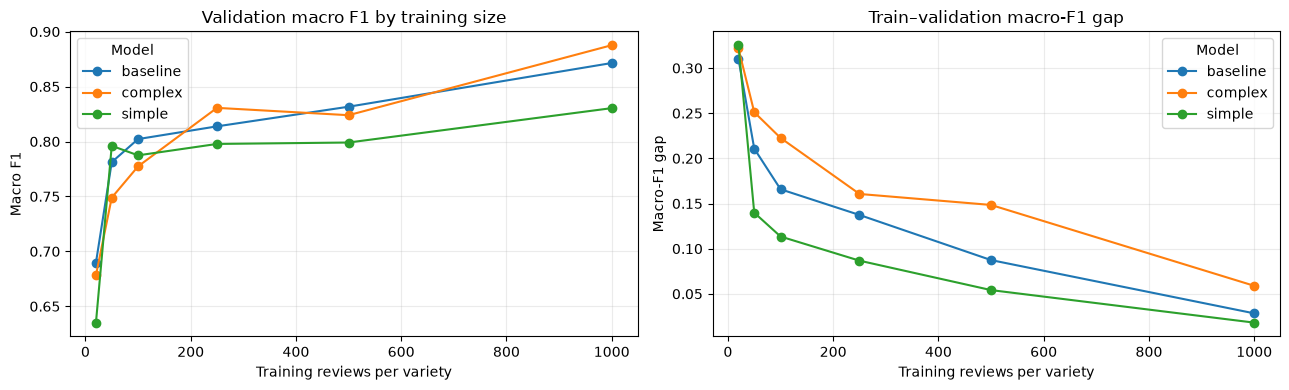

In [200]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
for model_name, group in learning_curve_results.groupby('model'):
    group = group.sort_values('train_per_variety')
    axes[0].plot(group['train_per_variety'], group['validation_macro_f1'], marker='o', label=model_name)
    axes[1].plot(group['train_per_variety'], group['macro_f1_gap'], marker='o', label=model_name)
axes[0].set(title='Validation macro F1 by training size', xlabel='Training reviews per variety', ylabel='Macro F1')
axes[1].set(title='Train–validation macro-F1 gap', xlabel='Training reviews per variety', ylabel='Macro-F1 gap')
for axis in axes:
    axis.grid(alpha=0.25)
    axis.legend(title='Model')
plt.tight_layout()
plt.show()

## Iteration 2: simple model at maximum balanced training size

Iteration 1 selected the simple unigram logistic-regression model at 1,000 training reviews per variety. This iteration keeps every model setting fixed and increases only the balanced training size to the maximum supported by the smallest variety in the French five-variety curve.

In [201]:
ITERATION_2_TRAIN_PER_VARIETY = curve_data['variety'].value_counts().min() - VALIDATION_PER_CLASS
ITERATION_2_CONFIG = next(config for config in MODELS if config['name'] == 'simple')

iteration_history = pd.DataFrame([
    {
        'iteration': 1,
        'change': 'Compared simple, baseline, and complex models across 20–1,000 nested training reviews per variety.',
        'selected_model': 'simple at 1,000 per variety',
    },
    {
        'iteration': 2,
        'change': 'Kept the simple model fixed and increased training size to the maximum balanced amount.',
        'selected_model': 'pending validation result',
    },
])
display(iteration_history)
print(f'Maximum balanced training reviews per variety: {ITERATION_2_TRAIN_PER_VARIETY:,}')
pd.DataFrame([ITERATION_2_CONFIG]).assign(max_features=MAX_FEATURES)

,iteration,change,selected_model
0,1,"Compared simple, baseline, and complex models across 20–1,000 nested training reviews per variety.","simple at 1,000 per variety"
1,2,Kept the simple model fixed and increased training size to the maximum balanced amount.,pending validation result


Maximum balanced training reviews per variety: 1,094


,name,ngram_range,min_df,C,max_features
0,simple,"(1, 1)",2,0.1,1000


In [202]:
iteration_2_train = nested_balanced_train(training_pool, ITERATION_2_TRAIN_PER_VARIETY)
iteration_2_model = make_logistic_model(ITERATION_2_CONFIG)
iteration_2_model.fit(iteration_2_train['model_text'], iteration_2_train['variety'])

iteration_2_train_prediction = iteration_2_model.predict(iteration_2_train['model_text'])
iteration_2_validation_prediction = iteration_2_model.predict(validation['model_text'])
iteration_2_results = pd.DataFrame([{
    'iteration': 2,
    'model': 'simple',
    'train_per_variety': ITERATION_2_TRAIN_PER_VARIETY,
    'train_rows': len(iteration_2_train),
    'validation_rows': len(validation),
    'train_accuracy': accuracy_score(iteration_2_train['variety'], iteration_2_train_prediction),
    'validation_accuracy': accuracy_score(validation['variety'], iteration_2_validation_prediction),
    'train_macro_f1': f1_score(iteration_2_train['variety'], iteration_2_train_prediction, average='macro', zero_division=0),
    'validation_macro_f1': f1_score(validation['variety'], iteration_2_validation_prediction, average='macro', zero_division=0),
}])
iteration_2_results['macro_f1_gap'] = iteration_2_results['train_macro_f1'] - iteration_2_results['validation_macro_f1']
display(iteration_2_results)

,iteration,model,train_per_variety,train_rows,validation_rows,train_accuracy,validation_accuracy,train_macro_f1,validation_macro_f1,macro_f1_gap
0,2,simple,1094,5470,125,0.849726,0.84,0.848774,0.838874,0.0099


## Iteration 3: regularize the maximum-data simple model

Iteration 2 showed that adding all available balanced training observations increased the generalization gap. Keep the same unigram representation, 1,000-feature cap, and 1,218 reviews per variety, while testing stronger L2 regularization.

In [203]:
ITERATION_3_TRAIN_PER_VARIETY = ITERATION_2_TRAIN_PER_VARIETY
ITERATION_3_CONFIGS = [
    {'name': 'simple_C0_1_reference', 'ngram_range': (1, 1), 'min_df': 2, 'C': 0.1},
    {'name': 'simple_C0_05', 'ngram_range': (1, 1), 'min_df': 2, 'C': 0.05},
    {'name': 'simple_C0_02', 'ngram_range': (1, 1), 'min_df': 2, 'C': 0.02},
    {'name': 'simple_C0_01', 'ngram_range': (1, 1), 'min_df': 2, 'C': 0.01},
]

iteration_history = pd.concat([
    iteration_history[iteration_history['iteration'] != 3],
    pd.DataFrame([{
        'iteration': 3,
        'change': 'Kept the maximum balanced training size and simple unigram features fixed; tested stronger L2 regularization.',
        'selected_model': 'pending validation result',
    }]),
], ignore_index=True)
display(iteration_history)
pd.DataFrame(ITERATION_3_CONFIGS).assign(train_per_variety=ITERATION_3_TRAIN_PER_VARIETY, max_features=MAX_FEATURES)

,iteration,change,selected_model
0,1,"Compared simple, baseline, and complex models across 20–1,000 nested training reviews per variety.","simple at 1,000 per variety"
1,2,Kept the simple model fixed and increased training size to the maximum balanced amount.,pending validation result
2,3,Kept the maximum balanced training size and simple unigram features fixed; tested stronger L2 regularization.,pending validation result


,name,ngram_range,min_df,C,train_per_variety,max_features
0,simple_C0_1_reference,"(1, 1)",2,0.10,1094,1000
1,simple_C0_05,"(1, 1)",2,0.05,1094,1000
2,simple_C0_02,"(1, 1)",2,0.02,1094,1000
3,simple_C0_01,"(1, 1)",2,0.01,1094,1000


In [204]:
iteration_3_train = nested_balanced_train(training_pool, ITERATION_3_TRAIN_PER_VARIETY)
iteration_3_results_rows = []

for config in ITERATION_3_CONFIGS:
    model = make_logistic_model(config)
    model.fit(iteration_3_train['model_text'], iteration_3_train['variety'])
    train_prediction = model.predict(iteration_3_train['model_text'])
    validation_prediction = model.predict(validation['model_text'])
    train_macro_f1 = f1_score(iteration_3_train['variety'], train_prediction, average='macro', zero_division=0)
    validation_macro_f1 = f1_score(validation['variety'], validation_prediction, average='macro', zero_division=0)
    iteration_3_results_rows.append({
        'iteration': 3,
        'model': config['name'],
        'C': config['C'],
        'train_per_variety': ITERATION_3_TRAIN_PER_VARIETY,
        'train_rows': len(iteration_3_train),
        'validation_rows': len(validation),
        'train_accuracy': accuracy_score(iteration_3_train['variety'], train_prediction),
        'validation_accuracy': accuracy_score(validation['variety'], validation_prediction),
        'train_macro_f1': train_macro_f1,
        'validation_macro_f1': validation_macro_f1,
        'macro_f1_gap': train_macro_f1 - validation_macro_f1,
    })

iteration_3_results = pd.DataFrame(iteration_3_results_rows).sort_values('validation_macro_f1', ascending=False)
display(iteration_3_results)

,iteration,model,C,train_per_variety,train_rows,validation_rows,train_accuracy,validation_accuracy,train_macro_f1,validation_macro_f1,macro_f1_gap
0,3,simple_C0_1_reference,0.10,1094,5470,125,0.849726,0.840,0.848774,0.838874,0.009900
1,3,simple_C0_05,0.05,1094,5470,125,0.830896,0.832,0.829311,0.830952,-0.001641
2,3,simple_C0_02,0.02,1094,5470,125,0.814077,0.824,0.811232,0.822179,-0.010947
3,3,simple_C0_01,0.01,1094,5470,125,0.804022,0.808,0.800177,0.805902,-0.005725


## Iteration 4: increase unigram vocabulary capacity

Iteration 1 showed that n-grams increase variance. This iteration keeps the winning unigram representation and 1,000-review training size fixed, then tests whether a slightly larger unigram vocabulary retains useful words without reintroducing the variance seen with bigrams and trigrams.

In [205]:
ITERATION_4_TRAIN_PER_VARIETY = 1_000
ITERATION_4_CONFIGS = [
    {'name': 'unigram_1000_C0_1_reference', 'ngram_range': (1, 1), 'min_df': 2, 'max_features': 1_000, 'C': 0.1},
    {'name': 'unigram_1500_C0_1', 'ngram_range': (1, 1), 'min_df': 2, 'max_features': 1_500, 'C': 0.1},
    {'name': 'unigram_1500_C0_05', 'ngram_range': (1, 1), 'min_df': 2, 'max_features': 1_500, 'C': 0.05},
    {'name': 'unigram_2000_C0_1', 'ngram_range': (1, 1), 'min_df': 2, 'max_features': 2_000, 'C': 0.1},
    {'name': 'unigram_2000_C0_05', 'ngram_range': (1, 1), 'min_df': 2, 'max_features': 2_000, 'C': 0.05},
]

iteration_history = pd.concat([
    iteration_history[iteration_history['iteration'] != 4],
    pd.DataFrame([{
        'iteration': 4,
        'change': 'Kept 1,000 training reviews per variety and unigrams fixed; increased maximum vocabulary from 1,000 to 1,500 and 2,000 features.',
        'selected_model': 'pending validation result',
    }]),
], ignore_index=True)
display(iteration_history)
pd.DataFrame(ITERATION_4_CONFIGS)

,iteration,change,selected_model
0,1,"Compared simple, baseline, and complex models across 20–1,000 nested training reviews per variety.","simple at 1,000 per variety"
1,2,Kept the simple model fixed and increased training size to the maximum balanced amount.,pending validation result
2,3,Kept the maximum balanced training size and simple unigram features fixed; tested stronger L2 regularization.,pending validation result
3,4,"Kept 1,000 training reviews per variety and unigrams fixed; increased maximum vocabulary from 1,000 to 1,500 and 2,0...",pending validation result


,name,ngram_range,min_df,max_features,C
0,unigram_1000_C0_1_reference,"(1, 1)",2,1000,0.10
1,unigram_1500_C0_1,"(1, 1)",2,1500,0.10
2,unigram_1500_C0_05,"(1, 1)",2,1500,0.05
3,unigram_2000_C0_1,"(1, 1)",2,2000,0.10
4,unigram_2000_C0_05,"(1, 1)",2,2000,0.05


In [206]:
iteration_4_train = nested_balanced_train(training_pool, ITERATION_4_TRAIN_PER_VARIETY)
iteration_4_results_rows = []

for config in ITERATION_4_CONFIGS:
    model = make_logistic_model(config)
    model.fit(iteration_4_train['model_text'], iteration_4_train['variety'])
    train_prediction = model.predict(iteration_4_train['model_text'])
    validation_prediction = model.predict(validation['model_text'])
    train_macro_f1 = f1_score(iteration_4_train['variety'], train_prediction, average='macro', zero_division=0)
    validation_macro_f1 = f1_score(validation['variety'], validation_prediction, average='macro', zero_division=0)
    iteration_4_results_rows.append({
        'iteration': 4,
        'model': config['name'],
        'C': config['C'],
        'max_features': config['max_features'],
        'train_per_variety': ITERATION_4_TRAIN_PER_VARIETY,
        'train_rows': len(iteration_4_train),
        'validation_rows': len(validation),
        'train_accuracy': accuracy_score(iteration_4_train['variety'], train_prediction),
        'validation_accuracy': accuracy_score(validation['variety'], validation_prediction),
        'train_macro_f1': train_macro_f1,
        'validation_macro_f1': validation_macro_f1,
        'macro_f1_gap': train_macro_f1 - validation_macro_f1,
    })

iteration_4_results = pd.DataFrame(iteration_4_results_rows).sort_values('validation_macro_f1', ascending=False)
display(iteration_4_results)

,iteration,model,C,max_features,train_per_variety,train_rows,validation_rows,train_accuracy,validation_accuracy,train_macro_f1,validation_macro_f1,macro_f1_gap
1,4,unigram_1500_C0_1,0.10,1500,1000,5000,125,0.8516,0.840,0.850751,0.838154,0.012597
3,4,unigram_2000_C0_1,0.10,2000,1000,5000,125,0.8540,0.840,0.853171,0.838154,0.015017
2,4,unigram_1500_C0_05,0.05,1500,1000,5000,125,0.8328,0.840,0.831155,0.838154,-0.006998
4,4,unigram_2000_C0_05,0.05,2000,1000,5000,125,0.8342,0.840,0.832507,0.838154,-0.005647
0,4,unigram_1000_C0_1_reference,0.10,1000,1000,5000,125,0.8494,0.832,0.848487,0.830371,0.018117


## Iteration 5: validate the selected model across repeated splits

Iterations 1–4 selected the simple unigram model with 1,000 TF–IDF features and `C=0.10`, trained on 1,000 reviews per variety. This iteration changes no model settings. It repeats the balanced train/validation split with several random seeds to estimate how sensitive validation macro F1 is to the particular review split.

In [207]:
ITERATION_5_SEEDS = [4401, 4402, 4403, 4404, 4405]
ITERATION_5_CONFIG = {
    'name': 'selected_simple_unigram',
    'ngram_range': (1, 1),
    'min_df': 2,
    'max_features': 1_000,
    'C': 0.1,
}
ITERATION_5_TRAIN_PER_VARIETY = 1_000

iteration_history = pd.concat([
    iteration_history[iteration_history['iteration'] != 5],
    pd.DataFrame([{
        'iteration': 5,
        'change': 'Held model settings and balanced sample sizes fixed; repeated train/validation splits across five random seeds.',
        'selected_model': 'pending split-stability result',
    }]),
], ignore_index=True)
display(iteration_history)
pd.DataFrame([ITERATION_5_CONFIG]).assign(train_per_variety=ITERATION_5_TRAIN_PER_VARIETY, validation_per_variety=VALIDATION_PER_CLASS)

,iteration,change,selected_model
0,1,"Compared simple, baseline, and complex models across 20–1,000 nested training reviews per variety.","simple at 1,000 per variety"
1,2,Kept the simple model fixed and increased training size to the maximum balanced amount.,pending validation result
2,3,Kept the maximum balanced training size and simple unigram features fixed; tested stronger L2 regularization.,pending validation result
3,4,"Kept 1,000 training reviews per variety and unigrams fixed; increased maximum vocabulary from 1,000 to 1,500 and 2,0...",pending validation result
4,5,Held model settings and balanced sample sizes fixed; repeated train/validation splits across five random seeds.,pending split-stability result


,name,ngram_range,min_df,max_features,C,train_per_variety,validation_per_variety
0,selected_simple_unigram,"(1, 1)",2,1000,0.1,1000,25


In [208]:
def make_seeded_balanced_split(frame, validation_per_class, train_per_class, seed):
    rng = np.random.default_rng(seed)
    validation_indices, train_indices = [], []
    for _, group in frame.groupby('variety', sort=True):
        indices = group.index.to_numpy().copy()
        rng.shuffle(indices)
        validation_indices.extend(indices[:validation_per_class])
        train_indices.extend(indices[validation_per_class:validation_per_class + train_per_class])
    return frame.loc[train_indices].copy(), frame.loc[validation_indices].copy()

iteration_5_rows = []
for seed in ITERATION_5_SEEDS:
    train_seeded, validation_seeded = make_seeded_balanced_split(
        curve_data, VALIDATION_PER_CLASS, ITERATION_5_TRAIN_PER_VARIETY, seed
    )
    model = make_logistic_model(ITERATION_5_CONFIG)
    model.fit(train_seeded['model_text'], train_seeded['variety'])
    train_prediction = model.predict(train_seeded['model_text'])
    validation_prediction = model.predict(validation_seeded['model_text'])
    train_macro_f1 = f1_score(train_seeded['variety'], train_prediction, average='macro', zero_division=0)
    validation_macro_f1 = f1_score(validation_seeded['variety'], validation_prediction, average='macro', zero_division=0)
    iteration_5_rows.append({
        'iteration': 5,
        'seed': seed,
        'train_rows': len(train_seeded),
        'validation_rows': len(validation_seeded),
        'train_macro_f1': train_macro_f1,
        'validation_macro_f1': validation_macro_f1,
        'macro_f1_gap': train_macro_f1 - validation_macro_f1,
    })

iteration_5_results = pd.DataFrame(iteration_5_rows)
iteration_5_summary = iteration_5_results[['train_macro_f1', 'validation_macro_f1', 'macro_f1_gap']].agg(['mean', 'std', 'min', 'max']).T
display(iteration_5_results)
display(iteration_5_summary)

,iteration,seed,train_rows,validation_rows,train_macro_f1,validation_macro_f1,macro_f1_gap
0,5,4401,5000,125,0.848487,0.830371,0.018117
1,5,4402,5000,125,0.848510,0.837881,0.010629
2,5,4403,5000,125,0.845611,0.856044,-0.010433
3,5,4404,5000,125,0.847476,0.839652,0.007824
4,5,4405,5000,125,0.849536,0.833178,0.016358


,mean,std,min,max
train_macro_f1,0.847924,0.001484,0.845611,0.849536
validation_macro_f1,0.839425,0.009995,0.830371,0.856044
macro_f1_gap,0.008499,0.011376,-0.010433,0.018117


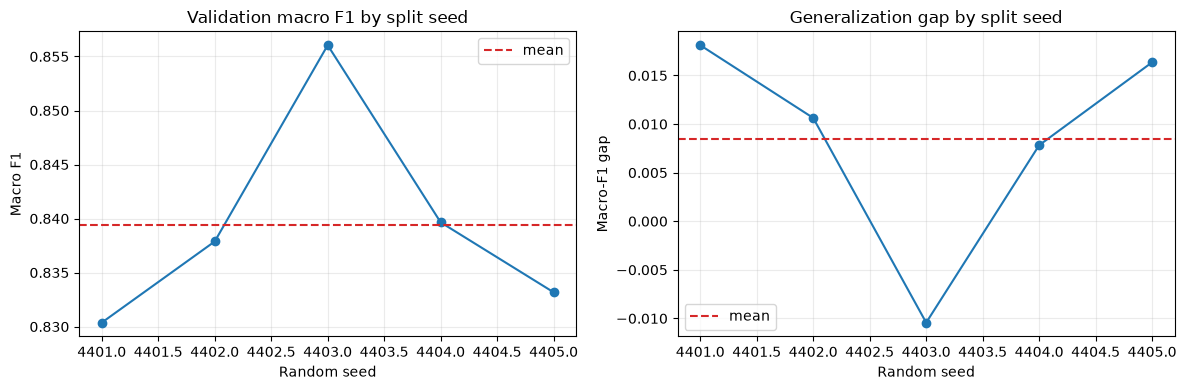

In [209]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].plot(iteration_5_results['seed'], iteration_5_results['validation_macro_f1'], marker='o')
axes[0].axhline(iteration_5_results['validation_macro_f1'].mean(), color='tab:red', linestyle='--', label='mean')
axes[0].set(title='Validation macro F1 by split seed', xlabel='Random seed', ylabel='Macro F1')
axes[1].plot(iteration_5_results['seed'], iteration_5_results['macro_f1_gap'], marker='o')
axes[1].axhline(iteration_5_results['macro_f1_gap'].mean(), color='tab:red', linestyle='--', label='mean')
axes[1].set(title='Generalization gap by split seed', xlabel='Random seed', ylabel='Macro-F1 gap')
for axis in axes:
    axis.grid(alpha=0.25)
    axis.legend()
plt.tight_layout()
plt.show()

## Iteration 6: strengthen validation with larger holdouts

Iteration 5 found meaningful split-to-split variation with only 25 validation reviews per variety. This iteration keeps the selected simple model and 1,000 training reviews per variety fixed, but doubles validation support to 50 reviews per variety.

In [210]:
ITERATION_6_SEEDS = [4401, 4402, 4403, 4404, 4405]
ITERATION_6_VALIDATION_PER_VARIETY = 50
ITERATION_6_TRAIN_PER_VARIETY = 1_000
ITERATION_6_CONFIG = ITERATION_5_CONFIG.copy()

minimum_required = ITERATION_6_VALIDATION_PER_VARIETY + ITERATION_6_TRAIN_PER_VARIETY
if curve_data['variety'].value_counts().min() < minimum_required:
    raise ValueError('The curve population does not support this train/validation allocation.')

iteration_history = pd.concat([
    iteration_history[iteration_history['iteration'] != 6],
    pd.DataFrame([{
        'iteration': 6,
        'change': 'Kept the selected model and 1,000 training reviews per variety fixed; increased validation support from 25 to 50 reviews per variety.',
        'selected_model': 'pending split-stability result',
    }]),
], ignore_index=True)
display(iteration_history)
pd.DataFrame([ITERATION_6_CONFIG]).assign(train_per_variety=ITERATION_6_TRAIN_PER_VARIETY, validation_per_variety=ITERATION_6_VALIDATION_PER_VARIETY)

,iteration,change,selected_model
0,1,"Compared simple, baseline, and complex models across 20–1,000 nested training reviews per variety.","simple at 1,000 per variety"
1,2,Kept the simple model fixed and increased training size to the maximum balanced amount.,pending validation result
2,3,Kept the maximum balanced training size and simple unigram features fixed; tested stronger L2 regularization.,pending validation result
3,4,"Kept 1,000 training reviews per variety and unigrams fixed; increased maximum vocabulary from 1,000 to 1,500 and 2,0...",pending validation result
4,5,Held model settings and balanced sample sizes fixed; repeated train/validation splits across five random seeds.,pending split-stability result
5,6,"Kept the selected model and 1,000 training reviews per variety fixed; increased validation support from 25 to 50 rev...",pending split-stability result


,name,ngram_range,min_df,max_features,C,train_per_variety,validation_per_variety
0,selected_simple_unigram,"(1, 1)",2,1000,0.1,1000,50


In [211]:
iteration_6_rows = []
for seed in ITERATION_6_SEEDS:
    train_seeded, validation_seeded = make_seeded_balanced_split(
        curve_data, ITERATION_6_VALIDATION_PER_VARIETY, ITERATION_6_TRAIN_PER_VARIETY, seed
    )
    model = make_logistic_model(ITERATION_6_CONFIG)
    model.fit(train_seeded['model_text'], train_seeded['variety'])
    train_prediction = model.predict(train_seeded['model_text'])
    validation_prediction = model.predict(validation_seeded['model_text'])
    train_macro_f1 = f1_score(train_seeded['variety'], train_prediction, average='macro', zero_division=0)
    validation_macro_f1 = f1_score(validation_seeded['variety'], validation_prediction, average='macro', zero_division=0)
    iteration_6_rows.append({
        'iteration': 6,
        'seed': seed,
        'train_rows': len(train_seeded),
        'validation_rows': len(validation_seeded),
        'train_macro_f1': train_macro_f1,
        'validation_macro_f1': validation_macro_f1,
        'macro_f1_gap': train_macro_f1 - validation_macro_f1,
    })

iteration_6_results = pd.DataFrame(iteration_6_rows)
iteration_6_summary = iteration_6_results[['train_macro_f1', 'validation_macro_f1', 'macro_f1_gap']].agg(['mean', 'std', 'min', 'max']).T
display(iteration_6_results)
display(iteration_6_summary)

,iteration,seed,train_rows,validation_rows,train_macro_f1,validation_macro_f1,macro_f1_gap
0,6,4401,5000,250,0.844306,0.843365,0.000941
1,6,4402,5000,250,0.850162,0.834834,0.015328
2,6,4403,5000,250,0.842896,0.855602,-0.012707
3,6,4404,5000,250,0.849395,0.803371,0.046023
4,6,4405,5000,250,0.848065,0.799745,0.048321


,mean,std,min,max
train_macro_f1,0.846965,0.003200,0.842896,0.850162
validation_macro_f1,0.827383,0.024737,0.799745,0.855602
macro_f1_gap,0.019581,0.027079,-0.012707,0.048321


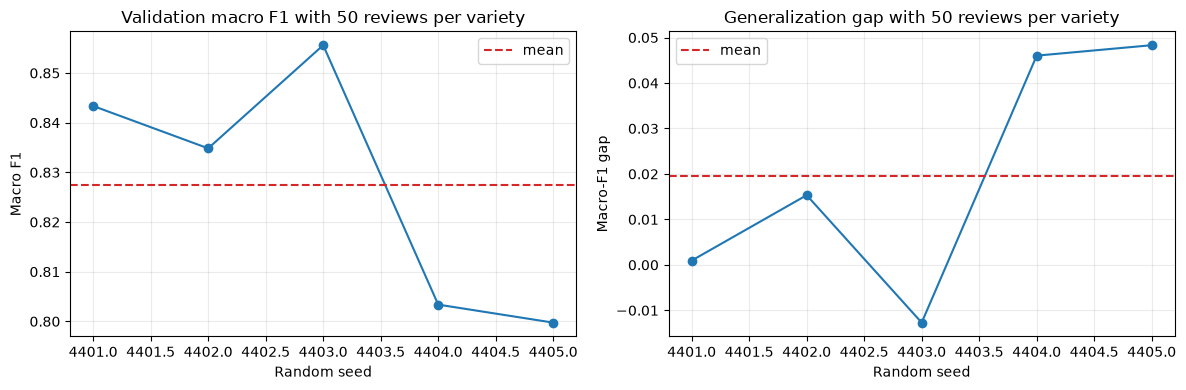

In [212]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].plot(iteration_6_results['seed'], iteration_6_results['validation_macro_f1'], marker='o')
axes[0].axhline(iteration_6_results['validation_macro_f1'].mean(), color='tab:red', linestyle='--', label='mean')
axes[0].set(title='Validation macro F1 with 50 reviews per variety', xlabel='Random seed', ylabel='Macro F1')
axes[1].plot(iteration_6_results['seed'], iteration_6_results['macro_f1_gap'], marker='o')
axes[1].axhline(iteration_6_results['macro_f1_gap'].mean(), color='tab:red', linestyle='--', label='mean')
axes[1].set(title='Generalization gap with 50 reviews per variety', xlabel='Random seed', ylabel='Macro-F1 gap')
for axis in axes:
    axis.grid(alpha=0.25)
    axis.legend()
plt.tight_layout()
plt.show()

## Iteration 7: five-fold stratified cross-validation

The repeated small balanced holdouts show that the selected model's score depends on the split. This iteration keeps the selected unigram model fixed and uses five non-overlapping stratified validation folds. Each fold trains on all other reviews in the five-variety French curve population. Class weights remain balanced, while macro F1 gives equal weight to each variety at evaluation.

In [213]:
ITERATION_7_CONFIG = {
    'name': 'selected_simple_unigram',
    'ngram_range': (1, 1),
    'min_df': 2,
    'max_features': 1_000,
    'C': 0.1,
}
ITERATION_7_FOLDS = 5

iteration_history = pd.concat([
    iteration_history[iteration_history['iteration'] != 7],
    pd.DataFrame([{
        'iteration': 7,
        'change': 'Held the selected model fixed and evaluated it using five non-overlapping stratified folds, training on all non-fold reviews.',
        'selected_model': 'pending cross-validation result',
    }]),
], ignore_index=True)
display(iteration_history)
pd.DataFrame([ITERATION_7_CONFIG]).assign(cv_folds=ITERATION_7_FOLDS, curve_reviews=len(curve_data), curve_varieties=curve_data['variety'].nunique())

,iteration,change,selected_model
0,1,"Compared simple, baseline, and complex models across 20–1,000 nested training reviews per variety.","simple at 1,000 per variety"
1,2,Kept the simple model fixed and increased training size to the maximum balanced amount.,pending validation result
2,3,Kept the maximum balanced training size and simple unigram features fixed; tested stronger L2 regularization.,pending validation result
3,4,"Kept 1,000 training reviews per variety and unigrams fixed; increased maximum vocabulary from 1,000 to 1,500 and 2,0...",pending validation result
4,5,Held model settings and balanced sample sizes fixed; repeated train/validation splits across five random seeds.,pending split-stability result
5,6,"Kept the selected model and 1,000 training reviews per variety fixed; increased validation support from 25 to 50 rev...",pending split-stability result
6,7,"Held the selected model fixed and evaluated it using five non-overlapping stratified folds, training on all non-fold...",pending cross-validation result


,name,ngram_range,min_df,max_features,C,cv_folds,curve_reviews,curve_varieties
0,selected_simple_unigram,"(1, 1)",2,1000,0.1,5,11398,5


In [214]:
cv = StratifiedKFold(n_splits=ITERATION_7_FOLDS, shuffle=True, random_state=RANDOM_STATE)
iteration_7_rows = []

for fold, (train_index, validation_index) in enumerate(cv.split(curve_data['model_text'], curve_data['variety']), start=1):
    train_fold = curve_data.iloc[train_index]
    validation_fold = curve_data.iloc[validation_index]
    model = make_logistic_model(ITERATION_7_CONFIG)
    model.fit(train_fold['model_text'], train_fold['variety'])
    train_prediction = model.predict(train_fold['model_text'])
    validation_prediction = model.predict(validation_fold['model_text'])
    train_macro_f1 = f1_score(train_fold['variety'], train_prediction, average='macro', zero_division=0)
    validation_macro_f1 = f1_score(validation_fold['variety'], validation_prediction, average='macro', zero_division=0)
    iteration_7_rows.append({
        'iteration': 7,
        'fold': fold,
        'train_rows': len(train_fold),
        'validation_rows': len(validation_fold),
        'train_macro_f1': train_macro_f1,
        'validation_macro_f1': validation_macro_f1,
        'macro_f1_gap': train_macro_f1 - validation_macro_f1,
    })

iteration_7_results = pd.DataFrame(iteration_7_rows)
iteration_7_summary = iteration_7_results[['train_macro_f1', 'validation_macro_f1', 'macro_f1_gap']].agg(['mean', 'std', 'min', 'max']).T
display(iteration_7_results)
display(iteration_7_summary)

,iteration,fold,train_rows,validation_rows,train_macro_f1,validation_macro_f1,macro_f1_gap
0,7,1,9118,2280,0.846545,0.814733,0.031811
1,7,2,9118,2280,0.839266,0.825294,0.013972
2,7,3,9118,2280,0.843841,0.813602,0.030239
3,7,4,9119,2279,0.844145,0.819521,0.024624
4,7,5,9119,2279,0.847478,0.824108,0.023371


,mean,std,min,max
train_macro_f1,0.844255,0.003190,0.839266,0.847478
validation_macro_f1,0.819452,0.005299,0.813602,0.825294
macro_f1_gap,0.024803,0.007037,0.013972,0.031811


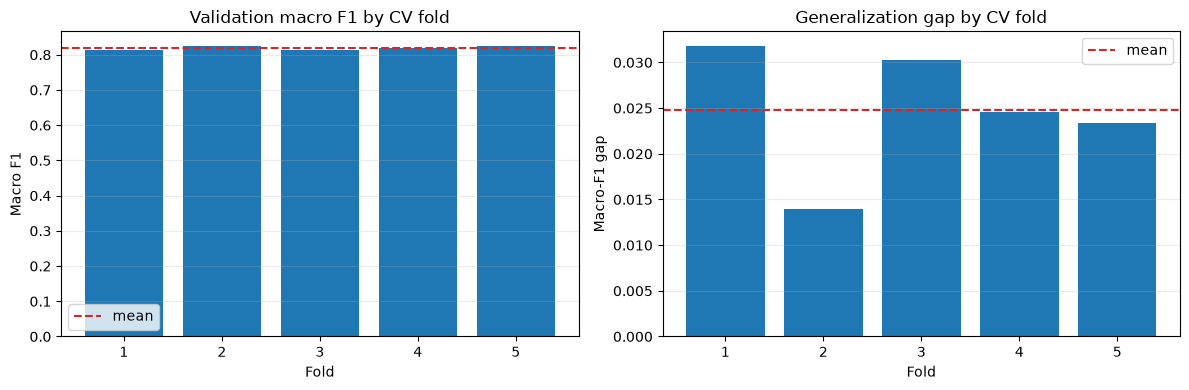

In [215]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].bar(iteration_7_results['fold'], iteration_7_results['validation_macro_f1'])
axes[0].axhline(iteration_7_results['validation_macro_f1'].mean(), color='tab:red', linestyle='--', label='mean')
axes[0].set(title='Validation macro F1 by CV fold', xlabel='Fold', ylabel='Macro F1')
axes[1].bar(iteration_7_results['fold'], iteration_7_results['macro_f1_gap'])
axes[1].axhline(iteration_7_results['macro_f1_gap'].mean(), color='tab:red', linestyle='--', label='mean')
axes[1].set(title='Generalization gap by CV fold', xlabel='Fold', ylabel='Macro-F1 gap')
for axis in axes:
    axis.grid(axis='y', alpha=0.25)
    axis.legend()
plt.tight_layout()
plt.show()

## Final Model

Run this section only after rerunning the earlier iterations on `development_data` and locking the selected configuration. The final test set was reserved before the iteration workflow and is used here exactly once. The final evaluation is limited to the French varieties that supported the learning curve.

In [216]:
FINAL_MODEL_CONFIG = {
    'name': 'selected_simple_unigram',
    'ngram_range': (1, 1),
    'min_df': 2,
    'max_features': 1_000,
    'C': 0.1,
}

final_test_curve = final_test[final_test['variety'].isin(curve_varieties)].copy()
if set(final_test_curve['variety']) != set(curve_varieties):
    raise ValueError('The final test set is missing one or more curve varieties.')

final_model = make_logistic_model(FINAL_MODEL_CONFIG)
final_model.fit(curve_data['model_text'], curve_data['variety'])
final_prediction = final_model.predict(final_test_curve['model_text'])

final_metrics = pd.DataFrame([{
    'model': FINAL_MODEL_CONFIG['name'],
    'development_rows': len(curve_data),
    'test_rows': len(final_test_curve),
    'test_accuracy': accuracy_score(final_test_curve['variety'], final_prediction),
    'test_macro_f1': f1_score(final_test_curve['variety'], final_prediction, average='macro', zero_division=0),
}])
final_class_report = pd.DataFrame(classification_report(
    final_test_curve['variety'], final_prediction, output_dict=True, zero_division=0
)).T

display(final_metrics)
display(final_class_report)

,model,development_rows,test_rows,test_accuracy,test_macro_f1
0,selected_simple_unigram,11398,1267,0.830308,0.805667


,precision,recall,f1-score,support
Bordeaux-style Red Blend,0.905405,0.849894,0.876772,473.000000
Champagne Blend,0.703125,0.725806,0.714286,124.000000
Chardonnay,0.904059,0.871886,0.887681,281.000000
Pinot Noir,0.665072,0.705584,0.684729,197.000000
Rosé,0.818605,0.916667,0.864865,192.000000
accuracy,0.830308,0.830308,0.830308,0.830308
macro avg,0.799253,0.813967,0.805667,1267.000000
weighted avg,0.834788,0.830308,0.831625,1267.000000


## Post-test EDA: Champagne Blend and Pinot Noir errors

This section explains the lower final-test F1 scores for Champagne Blend and Pinot Noir. It is diagnostic only: do not use these test-based findings to retune the final model.

In [217]:
FOCUS_VARIETIES = ['Champagne Blend', 'Pinot Noir']
test_error_data = final_test_curve.assign(predicted_variety=final_prediction).copy()
test_error_data['correct'] = test_error_data['variety'] == test_error_data['predicted_variety']
test_error_data['description_words'] = test_error_data['model_text'].str.split().str.len()
test_error_data['exact_label_mention'] = [
    str(variety).casefold() in str(text).casefold()
    for variety, text in zip(test_error_data['variety'], test_error_data['model_text'])
]

error_profile = test_error_data.groupby('variety').agg(
    test_reviews=('variety', 'size'),
    correct_rate=('correct', 'mean'),
    exact_label_mention_rate=('exact_label_mention', 'mean'),
    mean_description_words=('description_words', 'mean'),
).loc[FOCUS_VARIETIES]
display(error_profile)

labels = list(final_model.classes_)
confusion = pd.DataFrame(
    confusion_matrix(test_error_data['variety'], test_error_data['predicted_variety'], labels=labels),
    index=labels, columns=labels,
)
display(confusion.loc[FOCUS_VARIETIES])

,test_reviews,correct_rate,exact_label_mention_rate,mean_description_words
variety,,,,
Champagne Blend,124,0.725806,0.000000,41.935484
Pinot Noir,197,0.705584,0.060914,38.644670


,Bordeaux-style Red Blend,Champagne Blend,Chardonnay,Pinot Noir,Rosé
Champagne Blend,1,90,15,4,14
Pinot Noir,37,8,0,139,13


In [218]:
vectorizer = final_model.named_steps['tfidf']
classifier = final_model.named_steps['classifier']
feature_names = vectorizer.get_feature_names_out()

term_rows = []
for variety in FOCUS_VARIETIES:
    class_index = list(classifier.classes_).index(variety)
    top_indices = classifier.coef_[class_index].argsort()[-15:][::-1]
    for rank, term_index in enumerate(top_indices, start=1):
        term_rows.append({
            'variety': variety,
            'rank': rank,
            'model_term': feature_names[term_index],
            'coefficient': classifier.coef_[class_index, term_index],
        })
top_terms = pd.DataFrame(term_rows)
display(top_terms)

error_examples = test_error_data[
    test_error_data['variety'].isin(FOCUS_VARIETIES) & ~test_error_data['correct']
][['variety', 'predicted_variety', 'description']].groupby('variety', group_keys=False).head(5)
display(error_examples)

,variety,rank,model_term,coefficient
0,Champagne Blend,1,champagne,3.479207
1,Champagne Blend,2,bottle,2.082789
2,Champagne Blend,3,dosage,1.824485
3,Champagne Blend,4,apple,1.766944
4,Champagne Blend,5,style,1.556513
5,Champagne Blend,6,pinot,1.487152
6,Champagne Blend,7,mature,1.457143
7,Champagne Blend,8,dry,1.436934
8,Champagne Blend,9,nonvintage,1.336547
9,Champagne Blend,10,brut,1.334385


,variety,predicted_variety,description
51314,Pinot Noir,Rosé,"Owned by the Devillard family, Château de Chamirey produces firmly textured wines. This Mercurey is on the dry side,..."
8894,Pinot Noir,Bordeaux-style Red Blend,"Rich, opulent and spicy, with a great balance between wood and fruit. The generous black plum and black currant frui..."
59116,Champagne Blend,Bordeaux-style Red Blend,"A ripe, golden selection, glowing with a just-ready-to-drink feeling. From a fine vintage, this is structured and co..."
93291,Pinot Noir,Champagne Blend,"High acidity gives this wine freshness, while the fruitiness is somewhat more distant. It could age, but the bitter ..."
95019,Champagne Blend,Rosé,"A salmon-pink rosé, this wine is crisp with red cherry and raspberry flavors. Light and stylish, it offers a tangy t..."
75552,Champagne Blend,Rosé,"This is a special “Celebration 2000” bottling from this small family-run estate. The nose shows citrus and stone, wi..."
29804,Champagne Blend,Rosé,"Still young and fruity, this is a wine with impressive potential. For now, enjoy the palest of rosé colors, bright r..."
113224,Pinot Noir,Bordeaux-style Red Blend,"With crisp fruit well to the fore, this is a bright, lively wine. Its fruitiness is balanced by firm tannins that li..."
113666,Pinot Noir,Bordeaux-style Red Blend,"Tense and dark, this has firm, dry tannins that overlay black plum skin and black fig flavors. The wine shows richne..."
67372,Champagne Blend,Chardonnay,"This is an interesting bottling that opened up considerably while tasting. The nose displays biscuit, grape and lime..."


### Focused confusion and coefficient comparisons

The confusion table identifies observed test errors. The coefficient-margin tables then compare each lower-F1 variety with its most frequent predicted alternatives. A positive margin means the word favors the target variety over the alternative; a negative margin means it favors the alternative.

In [219]:
COMPARISON_GROUPS = {
    'Champagne Blend': ['Chardonnay', 'Rosé'],
    'Pinot Noir': ['Bordeaux-style Red Blend', 'Rosé'],
}

confusion_summary_rows = []
for actual_variety, alternatives in COMPARISON_GROUPS.items():
    actual_total = confusion.loc[actual_variety].sum()
    for predicted_variety in alternatives:
        errors = int(confusion.loc[actual_variety, predicted_variety])
        confusion_summary_rows.append({
            'actual_variety': actual_variety,
            'predicted_as': predicted_variety,
            'test_errors': errors,
            'share_of_actual_variety': errors / actual_total,
        })
confusion_summary = pd.DataFrame(confusion_summary_rows).sort_values(['actual_variety', 'test_errors'], ascending=[True, False])
display(confusion_summary)

pairwise_term_rows = []
for target, alternatives in COMPARISON_GROUPS.items():
    target_index = list(classifier.classes_).index(target)
    for alternative in alternatives:
        alternative_index = list(classifier.classes_).index(alternative)
        target_coef = classifier.coef_[target_index]
        alternative_coef = classifier.coef_[alternative_index]
        margin = target_coef - alternative_coef
        for direction, indices in [
            (f'favors {target}', margin.argsort()[-10:][::-1]),
            (f'favors {alternative}', margin.argsort()[:10]),
        ]:
            for term_index in indices:
                pairwise_term_rows.append({
                    'comparison': f'{target} vs {alternative}',
                    'direction': direction,
                    'term': feature_names[term_index],
                    f'{target}_coefficient': target_coef[term_index],
                    f'{alternative}_coefficient': alternative_coef[term_index],
                    'coefficient_margin': margin[term_index],
                })
pairwise_coefficient_terms = pd.DataFrame(pairwise_term_rows)
display(pairwise_coefficient_terms)

,actual_variety,predicted_as,test_errors,share_of_actual_variety
0,Champagne Blend,Chardonnay,15,0.120968
1,Champagne Blend,Rosé,14,0.112903
2,Pinot Noir,Bordeaux-style Red Blend,37,0.187817
3,Pinot Noir,Rosé,13,0.065990


,comparison,direction,term,Champagne Blend_coefficient,Chardonnay_coefficient,coefficient_margin,Rosé_coefficient,Pinot Noir_coefficient,Bordeaux-style Red Blend_coefficient
0,Champagne Blend vs Chardonnay,favors Champagne Blend,champagne,3.479207,-1.046715,4.525922,NaN,NaN,NaN
1,Champagne Blend vs Chardonnay,favors Champagne Blend,dry,1.436934,-1.712851,3.149785,NaN,NaN,NaN
2,Champagne Blend vs Chardonnay,favors Champagne Blend,red,-0.173788,-3.321882,3.148094,NaN,NaN,NaN
3,Champagne Blend vs Chardonnay,favors Champagne Blend,bottle,2.082789,-0.673216,2.756005,NaN,NaN,NaN
4,Champagne Blend vs Chardonnay,favors Champagne Blend,pinot,1.487152,-1.191997,2.679149,NaN,NaN,NaN
...,...,...,...,...,...,...,...,...,...
75,Pinot Noir vs Rosé,favors Rosé,estate,NaN,NaN,-1.747822,1.050504,-0.697318,NaN
76,Pinot Noir vs Rosé,favors Rosé,pepper,NaN,NaN,-1.713341,1.369476,-0.343866,NaN
77,Pinot Noir vs Rosé,favors Rosé,blend,NaN,NaN,-1.669883,0.788346,-0.881537,NaN
78,Pinot Noir vs Rosé,favors Rosé,grenache,NaN,NaN,-1.608212,1.306255,-0.301958,NaN


### Four report-ready coefficient tables

Each table isolates one observed error pair. The first ten rows contain terms that favor the actual target; the next ten contain terms that favor the competing predicted variety.

In [220]:
def coefficient_margin_table(target, alternative, top_n=10):
    target_index = list(classifier.classes_).index(target)
    alternative_index = list(classifier.classes_).index(alternative)
    target_coef = classifier.coef_[target_index]
    alternative_coef = classifier.coef_[alternative_index]
    margin = target_coef - alternative_coef

    target_rows = pd.DataFrame({
        'direction': f'favors {target}',
        'term': feature_names[margin.argsort()[-top_n:][::-1]],
        'target_coefficient': target_coef[margin.argsort()[-top_n:][::-1]],
        'alternative_coefficient': alternative_coef[margin.argsort()[-top_n:][::-1]],
        'coefficient_margin': margin[margin.argsort()[-top_n:][::-1]],
    })
    alternative_rows = pd.DataFrame({
        'direction': f'favors {alternative}',
        'term': feature_names[margin.argsort()[:top_n]],
        'target_coefficient': target_coef[margin.argsort()[:top_n]],
        'alternative_coefficient': alternative_coef[margin.argsort()[:top_n]],
        'coefficient_margin': margin[margin.argsort()[:top_n]],
    })
    return pd.concat([target_rows, alternative_rows], ignore_index=True)

REPORT_PAIRS = [
    ('Champagne Blend', 'Chardonnay'),
    ('Champagne Blend', 'Rosé'),
    ('Pinot Noir', 'Bordeaux-style Red Blend'),
    ('Pinot Noir', 'Rosé'),
]

report_coefficient_tables = {}
for target, alternative in REPORT_PAIRS:
    pair_name = f'{target} vs {alternative}'
    report_coefficient_tables[pair_name] = coefficient_margin_table(target, alternative)
    print(pair_name)
    display(report_coefficient_tables[pair_name])

Champagne Blend vs Chardonnay


,direction,term,target_coefficient,alternative_coefficient,coefficient_margin
0,favors Champagne Blend,champagne,3.479207,-1.046715,4.525922
1,favors Champagne Blend,dry,1.436934,-1.712851,3.149785
2,favors Champagne Blend,red,-0.173788,-3.321882,3.148094
3,favors Champagne Blend,bottle,2.082789,-0.673216,2.756005
4,favors Champagne Blend,pinot,1.487152,-1.191997,2.679149
5,favors Champagne Blend,dosage,1.824485,-0.480726,2.305211
6,favors Champagne Blend,style,1.556513,-0.544494,2.101007
7,favors Champagne Blend,blend,1.109899,-0.947270,2.057170
8,favors Champagne Blend,mature,1.457143,-0.518219,1.975362
9,favors Champagne Blend,balanced,1.331624,-0.544780,1.876404


Champagne Blend vs Rosé


,direction,term,target_coefficient,alternative_coefficient,coefficient_margin
0,favors Champagne Blend,champagne,3.479207,-1.280778,4.759984
1,favors Champagne Blend,apple,1.766944,-1.428373,3.195317
2,favors Champagne Blend,dosage,1.824485,-0.632011,2.456495
3,favors Champagne Blend,bottle,2.082789,-0.363874,2.446662
4,favors Champagne Blend,toast,1.055273,-1.173849,2.229122
5,favors Champagne Blend,pinot,1.487152,-0.709024,2.196176
6,favors Champagne Blend,mature,1.457143,-0.678225,2.135368
7,favors Champagne Blend,toasty,1.225865,-0.722677,1.948542
8,favors Champagne Blend,creamy,1.139978,-0.788165,1.928143
9,favors Champagne Blend,vintage,1.035209,-0.889237,1.924445


Pinot Noir vs Bordeaux-style Red Blend


,direction,term,target_coefficient,alternative_coefficient,coefficient_margin
0,favors Pinot Noir,red,3.148077,-1.653152,4.801228
1,favors Pinot Noir,cherry,2.454126,-1.040112,3.494238
2,favors Pinot Noir,strawberry,1.098126,-1.128171,2.226296
3,favors Pinot Noir,pinot,1.273232,-0.859364,2.132597
4,favors Pinot Noir,noir,1.265603,-0.708472,1.974075
5,favors Pinot Noir,raspberry,0.649572,-0.819500,1.469073
6,favors Pinot Noir,cherries,0.941177,-0.501017,1.442194
7,favors Pinot Noir,cru,0.650657,-0.706060,1.356717
8,favors Pinot Noir,perfumed,1.037182,-0.222015,1.259197
9,favors Pinot Noir,premier,0.681402,-0.558845,1.240247


Pinot Noir vs Rosé


,direction,term,target_coefficient,alternative_coefficient,coefficient_margin
0,favors Pinot Noir,tannins,2.862859,-2.286236,5.149095
1,favors Pinot Noir,structure,1.385877,-0.888114,2.273992
2,favors Pinot Noir,cherry,2.454126,0.217110,2.237016
3,favors Pinot Noir,wood,0.410543,-1.648932,2.059474
4,favors Pinot Noir,pinot,1.273232,-0.709024,1.982256
5,favors Pinot Noir,firm,1.104033,-0.875269,1.979302
6,favors Pinot Noir,years,0.736722,-1.079443,1.816165
7,favors Pinot Noir,juicy,0.745778,-1.062273,1.808051
8,favors Pinot Noir,dark,1.077741,-0.698835,1.776576
9,favors Pinot Noir,noir,1.265603,-0.445139,1.710742


### Error examples for each confusion pair

These are held-out test examples shown only to illustrate the already-reported final model errors. The predicted probability indicates how confidently the model selected the incorrect alternative.

In [221]:
ERROR_EXAMPLE_PAIRS = [
    ('Champagne Blend', 'Chardonnay'),
    ('Champagne Blend', 'Rosé'),
    ('Pinot Noir', 'Bordeaux-style Red Blend'),
    ('Pinot Noir', 'Rosé'),
]

test_probabilities = final_model.predict_proba(final_test_curve['model_text'])
predicted_class_index = {label: index for index, label in enumerate(final_model.classes_)}
test_error_data['predicted_probability'] = [
    probability[predicted_class_index[prediction]]
    for probability, prediction in zip(test_probabilities, test_error_data['predicted_variety'])
]
test_error_data['description_excerpt'] = test_error_data['description'].str.replace(r'\s+', ' ', regex=True).str.slice(0, 350)

pair_error_examples = {}
for actual, predicted in ERROR_EXAMPLE_PAIRS:
    pair_name = f'Actual {actual} → predicted {predicted}'
    examples = test_error_data[
        (test_error_data['variety'] == actual) &
        (test_error_data['predicted_variety'] == predicted)
    ].sort_values('predicted_probability', ascending=False)[
        ['variety', 'predicted_variety', 'predicted_probability', 'description_excerpt']
    ].head(5)
    pair_error_examples[pair_name] = examples
    print(pair_name)
    display(examples)

Actual Champagne Blend → predicted Chardonnay


,variety,predicted_variety,predicted_probability,description_excerpt
30485,Champagne Blend,Chardonnay,0.792740,"Although not labelled as a Blanc de Blancs, this pure Chardonnay wine is exactly that. It is a floral wine with roun..."
66880,Champagne Blend,Chardonnay,0.539059,"This ripe and creamy wine offers a good depth of flavor. It has plenty of fresh apple flavors, although the dominant..."
125862,Champagne Blend,Chardonnay,0.533559,"With a predominance of Chardonnay, this tightly crisp wine has a steely, mineral character. It is tight, tense and n..."
88320,Champagne Blend,Chardonnay,0.519498,"Intense is a good description of this tightly textured and mineral-driven wine. Its fruit is subdued by the steely, ..."
54990,Champagne Blend,Chardonnay,0.505569,"Soft and rounded with ripe apple and pear flavors, this wine expresses the richness of the vintage. Hints of toast a..."


Actual Champagne Blend → predicted Rosé


,variety,predicted_variety,predicted_probability,description_excerpt
95019,Champagne Blend,Rosé,0.784739,"A salmon-pink rosé, this wine is crisp with red cherry and raspberry flavors. Light and stylish, it offers a tangy t..."
68493,Champagne Blend,Rosé,0.665516,"Light and fruity, this gently textured wine is more about red fruits than structure. It is perfumed with red-berry f..."
81472,Champagne Blend,Rosé,0.585082,Red-currant aromas indicate this is a crisp style of rosé. Its red fruits are shot through with acidity and with a t...
83265,Champagne Blend,Rosé,0.517679,"This is a well-balanced wine, full of red fruits and with an attractive, deep salmon-pink color. It is ripe, showing..."
112038,Champagne Blend,Rosé,0.499904,"Soft raspberry juice with bubbles. It is a sweetened rosé, with only a hint of texture or acidity. For lovers of whi..."


Actual Pinot Noir → predicted Bordeaux-style Red Blend


,variety,predicted_variety,predicted_probability,description_excerpt
113666,Pinot Noir,Bordeaux-style Red Blend,0.690622,"Tense and dark, this has firm, dry tannins that overlay black plum skin and black fig flavors. The wine shows richne..."
8894,Pinot Noir,Bordeaux-style Red Blend,0.685018,"Rich, opulent and spicy, with a great balance between wood and fruit. The generous black plum and black currant frui..."
120413,Pinot Noir,Bordeaux-style Red Blend,0.667886,"This bold, well-structured wine is packed with both rich fruit and tannins. Dense black fruits are layered with a dr..."
104998,Pinot Noir,Bordeaux-style Red Blend,0.639242,"The wine has firm, dark tannins as befits a Pommard, with underlying sumptuous black fruit. As the tannins soften, t..."
5419,Pinot Noir,Bordeaux-style Red Blend,0.569616,This wine is fruity and ripe with fresh red-berry fruits and layers of smoky tannins. Those tannins will open up to ...


Actual Pinot Noir → predicted Rosé


,variety,predicted_variety,predicted_probability,description_excerpt
9099,Pinot Noir,Rosé,0.528893,"A delicious, crisp wine, with great bitter cherry and wild strawberry flavors and a high-definition streak of acidit..."
5806,Pinot Noir,Rosé,0.506233,"Hints of menthol and cherry cough drop are upfront on the nose. Flavors of red currant, rhubarb and sour raspberry a..."
68043,Pinot Noir,Rosé,0.487576,"Packed with red fruits, this is a ripe while fresh wine. Acidity that cuts into the ripe flavors with a crisp edge i..."
111522,Pinot Noir,Rosé,0.487016,Cherry and wild strawberry flavors dominate this fruity wine. It is very fresh with intense acidity and a crisp afte...
67268,Pinot Noir,Rosé,0.443116,A light and fruity wine with attractive red fruits and acidity. There is just a touch of tannin to hold the friendly...


## How to iterate

- Prefer the variant with the strongest validation macro F1 unless another has nearly equal validation F1 and a materially smaller gap.
- Keep `MAX_FEATURES = 1_000` fixed for this comparison.
- The curve uses only the five French varieties that support 1,000 training reviews plus validation. Do not compare its scores directly with a 22-variety French model.
- Do not create or consult a final test set until you select a model and training-size policy.